# Figure 2 — resting-state example bout and S1 functional connectivity

In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root =  str(PREPARES / "epochs-rest-to-running") + "/"
mouse='cm125'

In [4]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
sensory_ind['LM']=sensory_ind['mouth']
sensory_ind['LV']=extra_ind['LV']
sensory_ind['RV']=extra_ind['RV']

M2_ind['RM']=extra_extra_ind['right_mouth_motor']
M2_ind['LM']=M2_ind['mouth']

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_31113/407771601.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


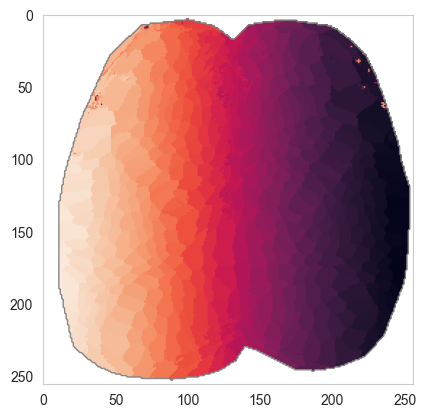

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
from skimage import measure
brain_contours = measure.find_contours(mask>-100, level=0.5)
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
        
    
plt.imshow(IDX_sorted)

In [6]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

sunset_cmap = load_pickle(figure_config_root+'sunset_cmap')

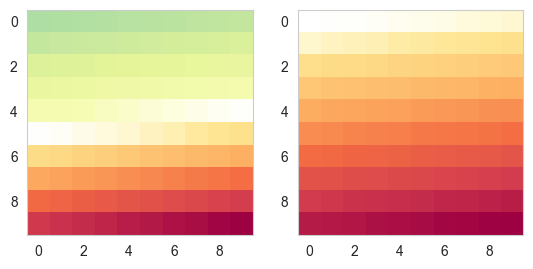

In [7]:
import matplotlib.colors as colors

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)


cmap = plt.get_cmap('Spectral_r')
sunset_above_cmap = truncate_colormap(sunset_cmap, 0.5, 1)

ax[0].imshow(arr, interpolation='nearest', cmap=sunset_cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=sunset_above_cmap)
plt.show()

**load rest-running bouts data**

In [8]:
load_list = ['norm_M_jrgeco', 'norm_M_rotf', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_pupil_pc_norm', 
 'norm_M_whisk_vel_norm', 'norm_M_nose_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_RFP_vel_norm',
 'M_day_label', 'M_is_groom', 'M_ind', 'norm_M_mirrorRFP_vel_norm', 'norm_M_mirrorLFP_vel_norm', 
 'norm_M_mirrorRHP_vel_norm', 'norm_M_mirrorLHP_vel_norm']

fetch_path_all_seed = str(PREPARES / "epochs-rest-to-running") + "/"


f = scipy.io.loadmat(fetch_path_all_seed+'final_'+mouse+'_norm.mat')

for item in load_list:
    exec("{}=np.squeeze(f['{}'])".format(item,item))
T_PRE=200;
T_POST=300;
T=T_PRE+T_POST

# zscore first
norm_M_jrgeco_zscore = norm_M_jrgeco.copy()
norm_M_jrgeco_zscore = stats.zscore(norm_M_jrgeco_zscore,axis=1)
ss = norm_M_jrgeco.shape
norm_M_jrgeco_zscore_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    temp = pd.DataFrame(norm_M_jrgeco_zscore[:,:,i_bout]).T.rolling(20).std().T.values
    norm_M_jrgeco_zscore_std=np.append(norm_M_jrgeco_zscore_std,temp[:,:,np.newaxis],axis=2)


In [9]:
palatte_dict['LT'] =  '#c4afaf' #'#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up


([<matplotlib.axis.YTick at 0x17372d0c0>,
 [Text(0, 0, 'LFP'), Text(0, 1, 'LW'), Text(0, 2, 'LM')])

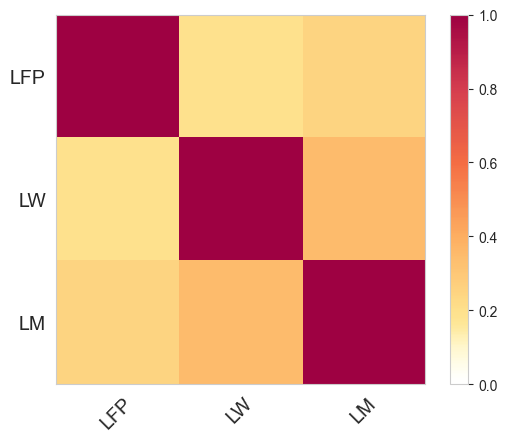

In [10]:
choice_S1_ind = {key:sensory_ind[key] for key in ['LFP','LW','LM']}
choice_corr_ind = {key:sensory_ind[key] for key in ['LFP','LW','LM']}
t_stop_resting_here = 160
df_corr=pd.DataFrame()
for i_count, key in enumerate(choice_S1_ind.keys()): 
    data_here = norm_M_jrgeco[choice_corr_ind[key],:t_stop_resting_here,:].flatten()
    df_corr[key] = data_here

plt.imshow(df_corr.corr(),cmap=sunset_above_cmap,vmin=0,vmax=1)
plt.colorbar()
plt.xticks(range(df_corr.select_dtypes(['number']).shape[1]), df_corr.select_dtypes(['number']).columns, fontsize=14, rotation=45)
plt.yticks(range(df_corr.select_dtypes(['number']).shape[1]), df_corr.select_dtypes(['number']).columns, fontsize=14)


# LOAD FULL DATA

In [11]:
i_bout = 16


In [12]:
ind_here = int(M_ind[i_bout]/3)
day_label_here = M_day_label[i_bout]
day = day_label_here.split('_')[1]
run_id = day_label_here.split('_')[2][:4]
f3 = list(set(glob.glob(step_1_root+mouse+"/["+day+"]/*"+run_id+"*.mat")))[0]
with h5py.File(f3,'r') as f_H: 
    m = f_H['m']
    nanidx = np.squeeze(m['nanidx'])==1
    C = np.array(f_H['C']['jrgeco'])
    S = np.array(f_H['S']['jrgeco'])[np.r_[ind_here-200:ind_here-75,ind_here-50:ind_here+160],:]
    mask = np.array(f_H['mask'])
    # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    CS = np.dot(S,C).transpose()
    jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
    jrgeco[:] = np.nan
    jrgeco[nanidx==True,:] = CS
    jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))



In [13]:
# load midline
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
norm_full_jrgeco = jrgeco - np.mean(jrgeco[:,:,:160],2)[:,:,np.newaxis]
norm_full_jrgeco = np.multiply(norm_full_jrgeco,mask_midline[:,:,np.newaxis])

In [14]:
norm_H = getH(norm_full_jrgeco,IDX_sorted)

In [15]:
tts = [50,64,88,105,137,153]

In [16]:
# RE-ORDER
choice_body_part_dict = {0:'LFP',1:'LW',2:'LM'}
choice_dict = {0:sensory_ind['LFP'],1:sensory_ind['LW'],2:sensory_ind['LM']}



In [17]:
mask = IDX_sorted >0
mask = mask.astype(float)
mask[mask==0]='nan'

M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp

masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
# plt.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)



In [18]:
palatte_dict['LW'] ='#501d8a' # LW
palatte_dict['LFP'] ='#95b7e3' # LFP


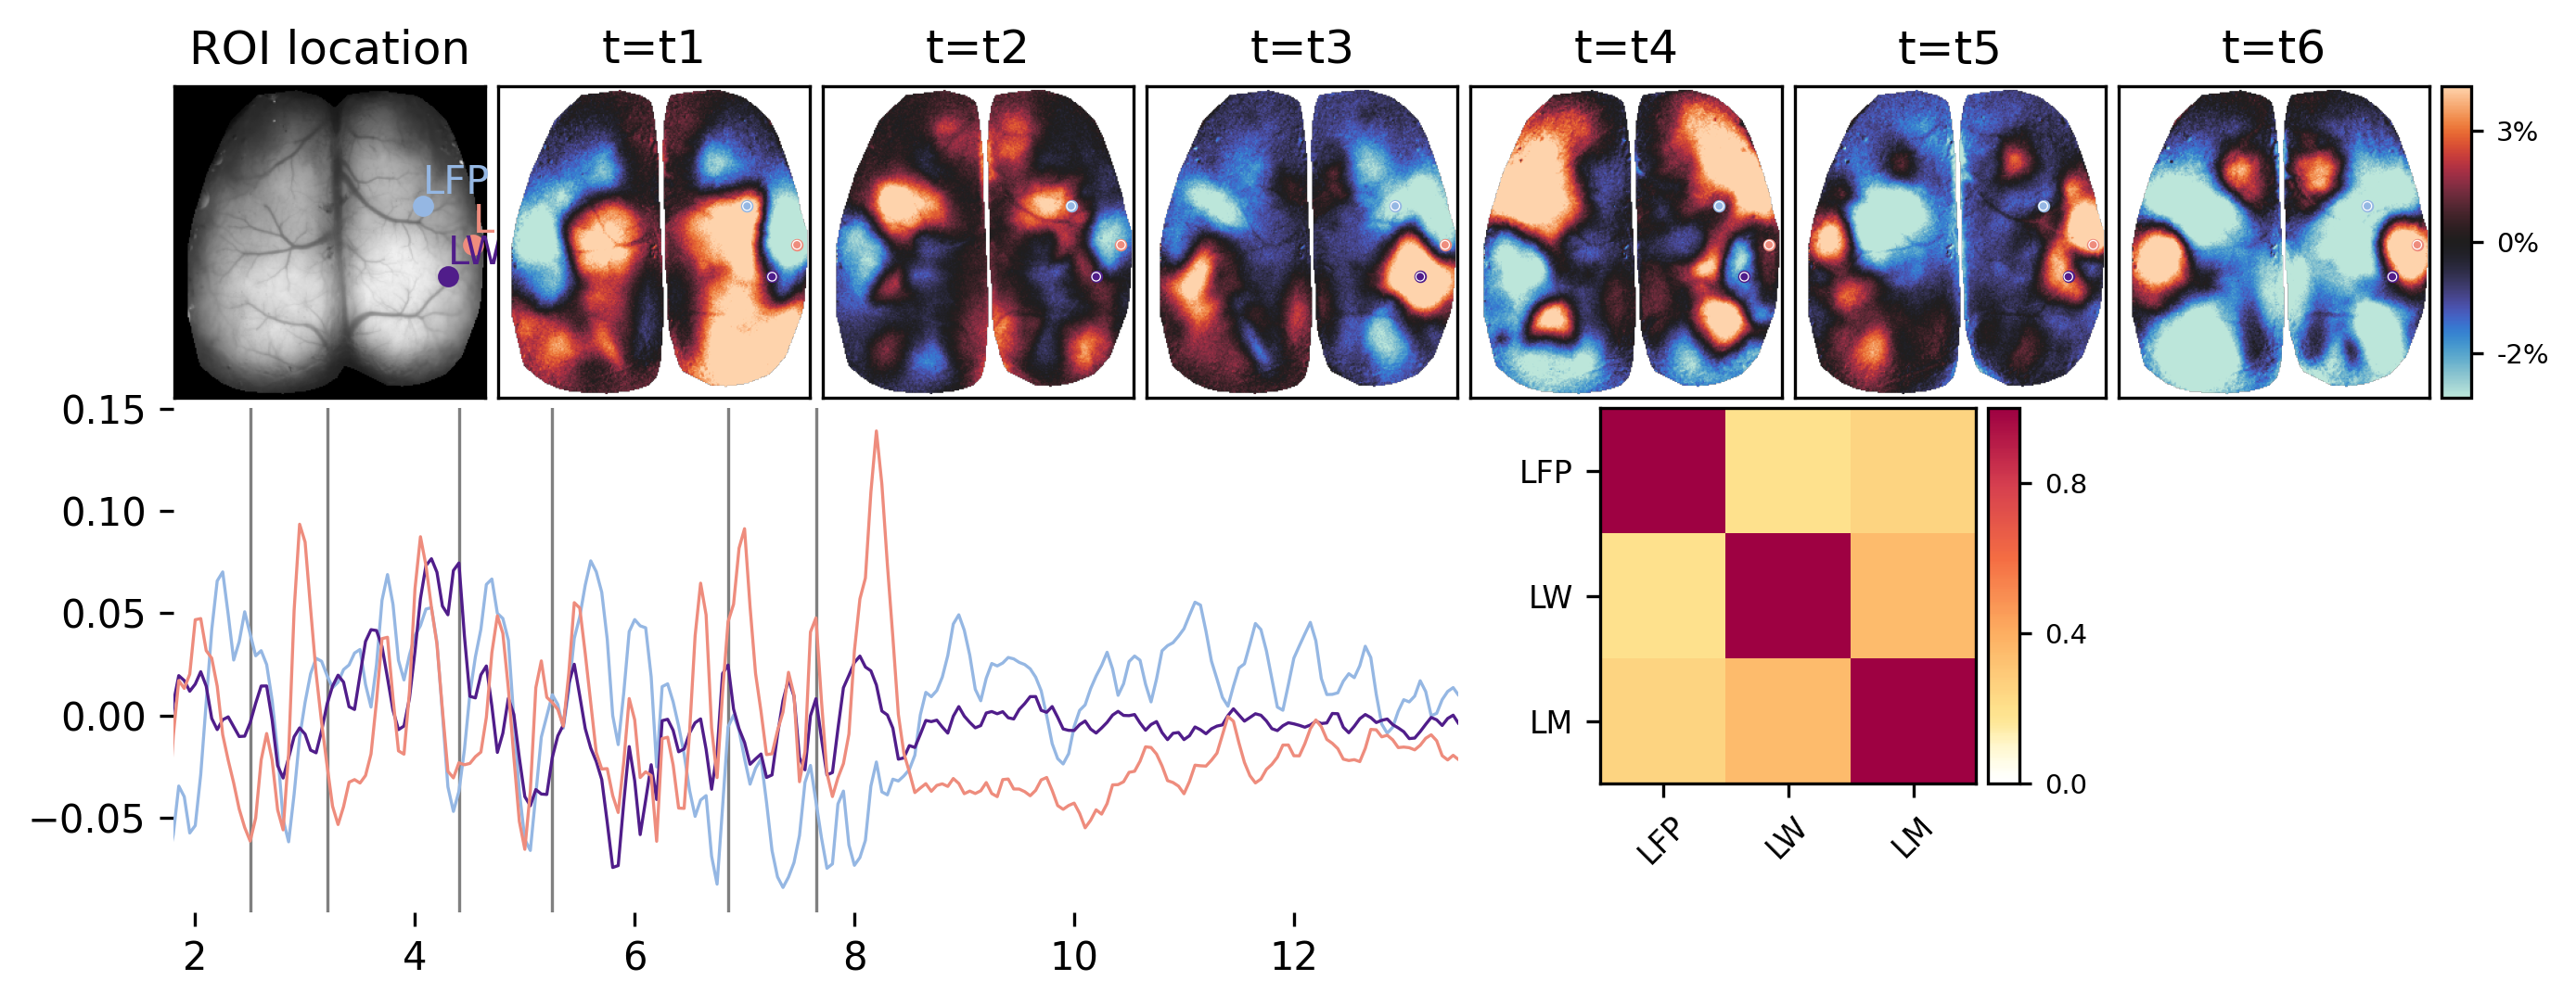

In [20]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width = 5; y_width = 5; y_gap = 1

x_start = x_offset
x_stop = x_start + x_width
y_start = y_offset
y_stop = y_start + y_width
for i_ax in range(7):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_start + 5 
    x_stop = x_start + x_width
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    
# ColorBar
ax99 = fig.add_subplot(gs[y_start:y_stop,x_start:x_start+1])

# TEMPORAL
x_start = x_offset 
x_stop = x_start + 20
y_start = y_stop + 0
y_stop = y_start + 8
ax7 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])

# CORRELATION MATRIX
x_start = x_stop+2 
x_stop = x_start + 6
y_stop = y_start + 6
ax8 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])
# ColorBar
ax999 = fig.add_subplot(gs[y_start:y_stop,x_stop:x_stop+1])


# ROI location
# add S1 contour
ax0.imshow(masked_brain,cmap='gray')
for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    bodypart_name_R = bdp
    ax0.scatter(node_coords[ind,1],node_coords[ind,0],s=20,color=palatte_dict[bdp])
    ax0.text(node_coords[ind,1],node_coords[ind,0]-10,bdp,
         color=palatte_dict[bdp])
ax0.set_title('ROI location')
        
        
# spatial maps
for i_ax,tt in enumerate(tts):
    i_ax+=1
    exec("sbp = ax{}.imshow(norm_full_jrgeco[:,:,tt],vmin=-0.035,vmax=0.035,cmap='icefire')".format(i_ax))
    for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
        ind = choice_dict[i_bdp]
        bdp = choice_body_part_dict[bdp_ind]
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_ax))
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,facecolors='none',linewidths=0.3, edgecolors='white')".format(i_ax))
        
    exec("ax{}.set_title('t=t{}')".format(i_ax,i_ax))
    
cb = fig.colorbar(sbp, cax=ax99,orientation='vertical',format=FuncFormatter(fmt));
cb.ax.tick_params(labelsize=7,length=3,color='black')
cb.ax.yaxis.tick_right()       
# cb.outline.set_edgecolor('gray')
# cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax99.set_aspect(150)
ax99.set_anchor('W')


#
t_stop_here = 330
my_xticks = np.divide(range(t_stop_here),20)
for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    ax7.plot(my_xticks,norm_H[ind,:t_stop_here]-np.mean(norm_H[ind,:160]),
             label=bdp,linewidth=0.8,color=palatte_dict[bdp])

for i_tt,tt in enumerate(tts):
    ax7.axvline(my_xticks[tt],linewidth=0.8,zorder=-500,color='gray')  
# 
ax7.set_xlim([1.8,13.5])
for axis in ['top','right','left','bottom']:
    ax7.spines[axis].set_linewidth(0)
    
    
    
    
from mpl_toolkits.axes_grid1 import make_axes_locatable
sbp8=ax8.imshow(df_corr.corr(),cmap=sunset_above_cmap,vmin=0,vmax=1)
cb = fig.colorbar(sbp8, cax=ax999,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='black')
cb.ax.yaxis.tick_right()       
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax999.set_aspect(12)
ax999.set_anchor('W')
ax8.set_xticks(range(df_corr.select_dtypes(['number']).shape[1]), df_corr.select_dtypes(['number']).columns, fontsize=8, rotation=45)
ax8.set_yticks(range(df_corr.select_dtypes(['number']).shape[1]), df_corr.select_dtypes(['number']).columns, fontsize=8)



plt.savefig('fig2-cortical-heterogeneity.svg',format='svg',dpi=300)